In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

/tmp/ipykernel_22344/687462750.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
DATA_PATH = '../../data'
MERGEGEN_RESULTS = '../../mergeGen/RESULTS'
SBCR_RESULTS = '../../sbcr'

MERGEGEN_DATASET1 = f"{MERGEGEN_RESULTS}/mergeGen_dataset1_model_dataset1_similarities.csv"
MERGEGEN_DATASET2_JAVA = f"{MERGEGEN_RESULTS}/mergeGen_dataset2_Java_model_dataset2_Java_similarities.csv"

SBCR_DATASET1 = f"{SBCR_RESULTS}/rq1_dataset1/RESULTS/results_evaluate_dataset1_rq1_dataset1_seed-3022024.xlsx"
SBCR_DATASET2 = f"{SBCR_RESULTS}/rq1_Java/RESULTS/results_evaluate_dataset2_Java_combination_rq1_Java_seed-3022024.xlsx"

DATASET2_COMPLETE = f"{DATA_PATH}/dataset2_complete.json" 
DATASET2_JAVA_TESTING = f"{DATA_PATH}/dataset2_Java_testing.json"
DATASET2_JAVA_METADATA = f"{DATA_PATH}/dataset2_Java_metadata.json"

DATASET1_COMPLETE = f"{DATA_PATH}/dataset1_complete.json" 
DATASET1_TESTING = f"{DATA_PATH}/dataset1_testing.json"
DATASET1_METADATA = f"{DATA_PATH}/dataset1_metadata.csv"

Find chunks that intersect at both datasets (dataset1 and dataset2_Java).
They will be removed later

In [3]:
dataset2_Java = pd.read_json(DATASET2_JAVA_TESTING)
dataset2_Java['chunk_id'] = dataset2_Java['merge_id'].astype(str) + '-' + dataset2_Java['chunk_number'].astype(str) 
dataset2_Java_metadata = pd.read_json(DATASET2_JAVA_METADATA)
dataset2_Java_metadata = dataset2_Java_metadata[dataset2_Java_metadata['chunk_id'].isin(list(dataset2_Java['chunk_id'].unique()))]
dataset1_metadata = pd.read_csv(DATASET1_METADATA)
dataset1 = pd.read_json(DATASET1_TESTING)
dataset1_metadata = dataset1_metadata[dataset1_metadata['chunk_id'].isin(list(dataset1['chunk_id'].unique()))]

In [4]:
intersection_dataset1 = list(dataset1_metadata[dataset1_metadata['sha'].isin(list(dataset2_Java_metadata['commitHash'].unique()))]['chunk_id'].unique())
intersection_dataset2 = list(dataset2_Java_metadata[dataset2_Java_metadata['commitHash'].isin(list(dataset1_metadata['sha'].unique()))]['chunk_id'].unique())

In [5]:
print(len(intersection_dataset2))
print(len(intersection_dataset1))

135
101


## Loading data from Dataset1

In [6]:
df_complete_ds1 = pd.read_json(DATASET1_COMPLETE)
df_complete_ds1

,all_raw_base,all_raw_a,all_raw_b,all_raw_res,chunk_id
0,\n ElementGraph sinkElementGraph = sinkProc...,this.outgoingOrdinals = createOrdinals( so...,this.sourceProcessID = sourceProcess.getID...,"\n // for both set of ordinals, we only car...",776782
1,this.ordinals = processEdge.getIncomingO...,this.ordinals = processEdge.getIncomingO...,this.ordinals = processEdge.getSourcePro...,this.ordinals = processEdge.getSourcePro...,776793
2,checkpointTap = makeTempTap( checkpoin...,checkpointTap = makeTempTap( checkpoin...,checkpointTap = makeTempTap( checkpoin...,checkpointTap = makeTempTap( checkpoin...,776929
3,import cascading.pipe.Pipe;\nimport cascading....,import cascading.flow.planner.graph.ElementGra...,import cascading.pipe.Pipe;\nimport cascading....,import cascading.flow.planner.graph.ElementGra...,776931
4,private final FlowProcess<Config> flowProces...,private final FlowProcess<? extends Config> ...,/** Field LOG */\n private static final Log...,/** Field LOG */\n private static final Log...,776942
...,...,...,...,...,...
6264,private DatabaseHelper mOpenHelper;\n,protected DatabaseHelper mOpenHelper;\n,private static final String TABLE_FAVORITE...,private static final String TABLE_FAVORITE...,1658620
6265,"\tpublic static String file = ""config.xml"";\n\...","\tpublic static String file = ""config.xml"";\n\...","\tpublic static final String file = ""config.xm...","\n\tpublic static final String file = ""config....",1658665
6266,"\tpublic static String file = ""config.xml"";\n\...","\tpublic static String file = ""config.xml"";\n\...","\tpublic static final String file = ""config.xm...","\n\tpublic static final String file = ""config....",1658666
6267,private boolean mIsScanModeSetDueToAHidden...,,private boolean mIsScanModeSetDueToAHidden...,private boolean mEnableRssiPolling;,1658029


In [7]:
df_test_ds1 = pd.read_json(DATASET1_TESTING)
df_test_ds1

,all_raw_base,all_raw_a,all_raw_b,all_raw_res,chunk_id
0,private final FlowProcess<Config> flowProces...,private final FlowProcess<? extends Config> ...,/** Field LOG */\n private static final Log...,/** Field LOG */\n private static final Log...,776942
1,import java.util.Collections;\nimport java.uti...,import java.util.Collections;\nimport java.uti...,,import javax.servlet.http.HttpServletRequest;,1014100
2,import static org.mockito.Mockito.when;\nimpor...,,import static org.mockito.Mockito.when;\nimpor...,import org.junit.Assert.*;\nimport org.zanata....,1019530
3,import org.broadinstitute.sting.utils.help.Hel...,import org.broadinstitute.sting.utils.help.Hel...,import org.broadinstitute.sting.utils.help.Hel...,import org.broadinstitute.variant.variantconte...,1082450
4,mSubkeysAddedAdapter = new SubkeysAdde...,mSubkeysAddedAdapter = new SubkeysAdde...,mSubkeysList.setOnItemClickListener(ne...,mSubkeysList.setOnItemClickListener(ne...,1370321
...,...,...,...,...,...
623,if (getKeyspaces().contains(keyspaceName...,try {\n KsDef keyspaceDesc = cass...,if (getKeyspaces().contains(keyspaceName...,try {\n KsDef keyspaceDesc = cass...,936821
624,int len = mQuery.mSql.length()...,int len = mQuery.mSql.length()...,if (StrictMode.vmSqliteObjectL...,if (StrictMode.vmSqliteObjectL...,1182256
625,if (logger.isDebug...,if (logger.isDebug...,if (LOG.isDebugEna...,if (LOG.isDebugEna...,1401191
626,InetSocketAddress namenode = NameNode.getA...,"this.dfs = new DFSClient(uri, conf, statis...",InetSocketAddress namenode = NameNode.getA...,"this.dfs = new DFSClient(uri, conf, statis...",932859


In [8]:
df_mergegen_ds1 = pd.read_csv(MERGEGEN_DATASET1)
df_mergegen_ds1

,chunk_index,similarity,complete_similarity,time,v1_similarity,v2_similarity,parents_similarity,result
0,5019,0.259615,0.272222,0.117003,1.000000,0.252577,0.626289,FAIL
1,3899,0.733333,0.741379,0.116758,0.593103,0.000000,0.296552,FAIL
2,4351,0.710843,0.716981,0.130520,0.000000,0.716981,0.358491,FAIL
3,5574,0.657143,0.671642,0.123770,0.494382,0.537143,0.515762,FAIL
4,6210,0.250373,0.259194,1.323702,0.000000,0.510092,0.255046,FAIL
...,...,...,...,...,...,...,...,...
623,5998,0.685417,0.804124,1.324466,0.764862,0.732394,0.748628,SUCCEED
624,4227,0.662712,0.754717,1.319163,0.446171,0.769032,0.607602,SUCCEED
625,5516,1.000000,1.000000,0.227891,0.615942,0.800000,0.707971,SUCCEED
626,814,0.685417,0.804124,1.318304,0.764862,0.732394,0.748628,SUCCEED


In [9]:
df_mergegen_ds1.describe()

,chunk_index,similarity,complete_similarity,time,v1_similarity,v2_similarity,parents_similarity
count,628.000000,628.000000,628.000000,628.000000,628.000000,628.000000,628.000000
mean,3186.826433,0.922931,0.923022,0.397476,0.684631,0.664965,0.674798
std,1783.523962,0.150310,0.153027,0.339692,0.294746,0.296725,0.219564
min,4.000000,0.211321,0.082251,0.051868,0.000000,0.000000,0.066852
25%,1629.750000,0.937367,0.940939,0.156820,0.578026,0.545694,0.530454
50%,3241.500000,1.000000,1.000000,0.277324,0.773601,0.750887,0.738113
75%,4676.000000,1.000000,1.000000,0.509618,0.912343,0.895033,0.845201
max,6240.000000,1.000000,1.000000,1.331165,1.000000,1.000000,0.983675


In [10]:
df_mergegen_ds1['chunk_id'] = df_mergegen_ds1['chunk_index'].apply(lambda idx: df_complete_ds1.loc[idx, 'chunk_id'])
df_mergegen_ds1 = df_mergegen_ds1.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})
df_mergegen_ds1 = df_mergegen_ds1[~df_mergegen_ds1['chunk_id'].isin(intersection_dataset1)]
df_mergegen_ds1.sort_values('chunk_id')

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result,chunk_id
178,7,1.000000,0.994764,0.233733,0.933702,0.838906,0.886304,SUCCEED,777222
446,19,0.967742,1.000000,0.751554,0.973190,0.551456,0.762323,SUCCEED,777715
145,53,0.530120,0.545455,0.163389,0.321429,0.724138,0.522783,FAIL,777972
152,55,0.752577,0.804533,1.326094,0.000000,0.802260,0.401130,FAIL,777981
190,58,0.658800,0.619327,1.331165,0.578393,0.369996,0.474195,SUCCEED,778117
...,...,...,...,...,...,...,...,...,...
449,6208,1.000000,1.000000,0.254737,0.981308,0.437956,0.709632,SUCCEED,1653719
4,6210,0.250373,0.259194,1.323702,0.000000,0.510092,0.255046,FAIL,1653901
314,6228,1.000000,1.000000,0.153870,0.000000,0.821918,0.410959,SUCCEED,1656072
602,6236,1.000000,1.000000,0.280683,0.923977,0.858696,0.891336,SUCCEED,1656401


In [11]:
df_sbcr_ds1 = pd.read_excel(SBCR_DATASET1)
df_sbcr_ds1 = df_sbcr_ds1.rename(columns={"solution_sim_lcs": "sim_sbcr", "time_seconds": "time_sbcr", "fitness": "fitness_sbcr"})
df_sbcr_ds1 = df_sbcr_ds1[~df_sbcr_ds1['chunk_id'].isin(intersection_dataset1)]
df_sbcr_ds1.sort_values('chunk_id')

,chunk_id,fitness_sbcr,sim_sbcr,status,time_sbcr
304,777222,0.890922,0.995192,ok,0.841280
186,777715,0.776531,0.985915,ok,0.333870
585,777972,0.739558,0.918239,ok,2.215153
257,777981,0.493671,1.000000,ok,1.991492
426,778117,0.740639,0.573416,ok,11.904242
...,...,...,...,...,...
468,1653719,0.702732,1.000000,ok,1.030614
140,1653901,0.492901,0.192205,ok,6.408932
296,1656072,0.498986,0.810680,ok,12.752023
530,1656401,0.901249,0.788274,ok,0.941998


In [12]:
df_results_ds1 = df_sbcr_ds1[['chunk_id', 'fitness_sbcr', 'sim_sbcr', 'time_sbcr']].merge(df_mergegen_ds1[['chunk_index', 'chunk_id', 'sim_mergegen', 'time_mergegen', 'mergegen_parents_sim']], on='chunk_id', suffixes=('_sbcr', '_mergegen'))
df_results_ds1

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim
0,938488,0.962434,0.922330,1.200660,1471,1.000000,0.175078,0.958965
1,1079827,0.497797,0.625767,11.268360,3195,1.000000,0.209426,0.318471
2,1117164,0.786942,0.786232,1.923556,3761,0.750751,0.227764,0.670922
3,945817,0.795430,0.819499,1.355437,1594,0.817844,0.423918,0.757170
4,1304099,0.459559,0.763636,8.889821,4944,1.000000,0.247783,0.397321
...,...,...,...,...,...,...,...,...
522,938165,0.819818,1.000000,10.783195,1443,1.000000,0.195416,0.819331
523,1517141,0.901249,0.788274,0.200084,5997,1.000000,0.280220,0.891336
524,934974,0.897614,0.857708,0.521170,1221,1.000000,0.463721,0.915444
525,1180810,0.591401,0.915108,1.287984,4423,0.967423,1.103757,0.566233


## Loading data from Dataset2

In [13]:
df_complete_ds2 = pd.read_json(DATASET2_COMPLETE)

In [14]:
df_test_ds2 = pd.read_json(DATASET2_JAVA_TESTING)
df_test_ds2

,all_raw_base,all_raw_a,all_raw_b,all_raw_res,merge_id,chunk_number
0,,this.config.setFilterBranchName(filter...,\n this.config.getContent().setShowTrig...,this.config.setFilterBranchName(filter...,201013,5
1,if (!updatedSubscribers.add(s.getSup...,if (!updatedSubscribers.add(s.getSup...,\n try {\n if (!updatedSub...,try {\n if (!updatedSubsc...,7891,2
2,"volumeData.add(new Pair<String, Ob...",volResponse.setDiskOfferingId(volu...,"\n volumeData.add(new Pair<String, ...",volResponse.setDiskOfferingId(volu...,218666,3
3,,import net.minecraft.pathfinding.PathNavigator;\n,\nimport net.minecraft.potion.EffectInstance;\...,import net.minecraft.pathfinding.PathNavigator...,272664,1
4,\n,,\n \n public JSONObject sanitizeJson(Htt...,\n public JSONObject sanitizeJson(HttpS...,55721,2
...,...,...,...,...,...,...
6570,processor = MessageMappingProcesso...,processor = MessageMappingProcesso...,\n processor = MessageMappingProces...,processor = MessageMappingProcesso...,177280,2
6571,\t\t\t\t// Meta.g:1:360: T_TERM\n,\t\t\t\t// Meta.g:1:326: T_UDF\n,\n\t\t\t\t// Meta.g:1:341: T_CLUSTERING\n,,101077,97
6572,"Position prev = new Position(0, 0, 0, ...","Position prev = new Position(0, 0, 0, ...",\n EntityPlayer player = runner.outside...,EntityPlayer player = runner.outside.a...,15144,1
6573,* @return true if the workflow has comple...,* @return true if the workflow has comple...,\n * @return true if the workflow is in te...,* @return true if the workflow has comple...,39379,16


In [15]:
df_mergegen_ds2 = pd.read_csv(MERGEGEN_DATASET2_JAVA)
data = []
for index, row in df_mergegen_ds2.iterrows():
    chunk = df_complete_ds2.iloc[row['chunk_index']]
    chunk_id = f"{chunk['merge_id']}-{chunk['chunk_number']}"
    data.append(chunk_id)
df_mergegen_ds2['chunk_id'] = data
df_mergegen_ds2 = df_mergegen_ds2.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})

# remove the chunks that intersect with dataset1
df_mergegen_ds2 = df_mergegen_ds2[~df_mergegen_ds2['chunk_id'].isin(intersection_dataset2)]
df_mergegen_ds2

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result,chunk_id
0,59484,0.000000,0.000000,1.323704,0.242101,0.810920,0.526510,FAIL,228576-22
1,1491,0.980392,0.958333,0.065673,0.958333,1.000000,0.979167,FAIL,214661-2
2,27472,0.000000,0.000000,0.624698,0.910688,0.000000,0.455344,FAIL,190323-10
3,44031,0.639344,0.620690,0.132782,0.696629,0.635294,0.665962,FAIL,267141-1
4,30780,0.000000,0.000000,0.472381,1.000000,0.000000,0.500000,FAIL,91505-1
...,...,...,...,...,...,...,...,...,...
6570,20687,1.000000,1.000000,0.185633,0.416938,1.000000,0.708469,SUCCEED,247986-2
6571,17318,0.642424,0.574427,1.345178,0.572658,0.370607,0.471632,SUCCEED,251982-2
6572,45321,1.000000,1.000000,0.242553,1.000000,0.691667,0.845833,SUCCEED,192296-2
6573,18608,1.000000,1.000000,0.308121,0.000000,1.000000,0.500000,SUCCEED,52782-1


In [16]:
df_mergegen_ds2.describe()

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim
count,6440.000000,6440.000000,6440.000000,6440.000000,6440.000000,6440.000000,6440.000000
mean,32608.719255,0.858335,0.852717,0.476933,0.682609,0.689204,0.685906
std,18966.232183,0.255347,0.270453,0.411268,0.335390,0.329416,0.215286
min,4.000000,0.000000,0.000000,0.038898,0.000000,0.000000,0.000000
25%,16104.500000,0.784278,0.826446,0.187333,0.509711,0.529757,0.500000
50%,32529.500000,1.000000,1.000000,0.314569,0.808081,0.812500,0.687826
75%,49055.250000,1.000000,1.000000,0.590783,0.960271,0.960000,0.875129
max,65732.000000,1.000000,1.000000,1.402251,1.000000,1.000000,1.000000


In [17]:
df_sbcr_ds2 = pd.read_excel(SBCR_DATASET2)
df_sbcr_ds2 = df_sbcr_ds2.rename(columns={"solution_sim_lcs": "sim_sbcr", "time_seconds": "time_sbcr", "fitness": "fitness_sbcr"})
df_sbcr_ds2 = df_sbcr_ds2[~df_sbcr_ds2['chunk_id'].isin(intersection_dataset2)]
df_sbcr_ds2.sort_values('chunk_id')

,chunk_id,fitness_sbcr,sim_sbcr,status,time_sbcr
1416,100103-5,0.678223,0.834081,ok,0.083678
442,100173-1,0.838751,0.986547,ok,0.212151
1911,100427-3,0.861423,1.000000,ok,0.156260
233,100495-1,0.814207,0.826597,ok,2.114276
1474,100725-1,0.931273,0.973747,ok,1.728550
...,...,...,...,...,...
1813,99569-21,0.823177,0.937755,ok,11.167688
55,99584-2,0.813481,0.914191,ok,0.225970
400,99678-3,0.503030,0.880734,ok,0.138450
598,99784-8,0.829048,1.000000,ok,0.991337


In [18]:
df_results_ds2 = df_sbcr_ds2[['chunk_id', 'fitness_sbcr', 'sim_sbcr', 'time_sbcr']].merge(df_mergegen_ds2[['chunk_index', 'chunk_id', 'sim_mergegen', 'time_mergegen', 'mergegen_parents_sim']], on='chunk_id', suffixes=('_sbcr', '_mergegen'))
df_results_ds2

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim
0,247633-11,0.772002,0.413502,0.195323,37554,1.000000,0.098506,0.589247
1,218430-3,0.947421,1.000000,0.825038,59863,1.000000,0.190504,0.939097
2,64045-1,0.979891,0.981432,2.291695,5235,1.000000,0.299400,0.979356
3,276497-1,0.844135,1.000000,0.300525,28978,0.984456,0.360160,0.838726
4,228270-4,0.741226,0.818408,0.874901,19428,1.000000,1.350036,0.723848
...,...,...,...,...,...,...,...,...
1931,258478-4,0.978495,1.000000,1.557349,35832,1.000000,0.380552,0.977431
1932,167370-1,0.688285,0.506004,10.421561,17374,0.711382,1.345684,0.604090
1933,91740-2,0.795016,0.793651,2.451555,55023,0.696629,0.246882,0.788434
1934,136898-33,0.968289,0.991394,0.611825,39157,1.000000,0.545362,0.982399


In [19]:
df_results = pd.concat([df_results_ds1, df_results_ds2])

In [20]:
print(df_results['sim_sbcr'].isnull().sum()) 
df_results_clean = df_results.dropna(subset=['sim_sbcr', 'sim_mergegen'])

24


In [21]:
print(df_results_clean[['sim_sbcr', 'sim_mergegen', 'time_sbcr', 'time_mergegen']].describe())

          sim_sbcr  sim_mergegen    time_sbcr  time_mergegen
count  2439.000000   2439.000000  2439.000000    2439.000000
mean      0.799303      0.900331     4.151721       0.475521
std       0.205857      0.193174     9.004529       0.390787
min       0.013072      0.000000     0.066401       0.039297
25%       0.678366      0.881089     0.377973       0.203672
50%       0.861423      1.000000     1.267573       0.326955
75%       0.977011      1.000000     3.767674       0.581761
max       1.000000      1.000000   186.743766       1.402251


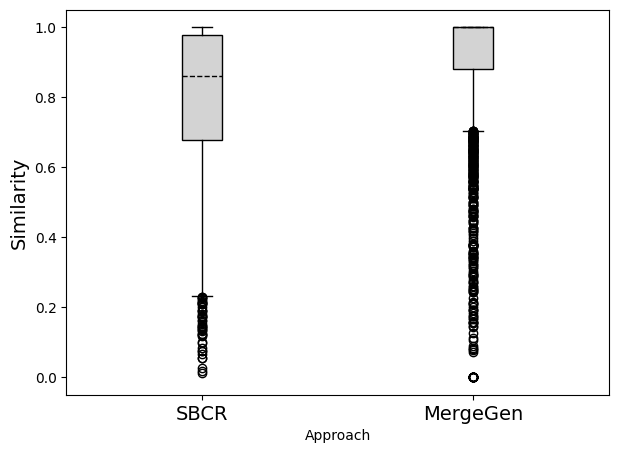

In [22]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_results_clean['sim_sbcr'], df_results_clean['sim_mergegen']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=True)

plt.xlabel('Approach')
plt.ylabel('Similarity', fontsize=14)
plt.xticks([1, 2], ['SBCR', 'MergeGen'], fontsize=14)
# plt.title('Similarity between random candidates and parents \n using each aggregation function', fontsize=16)

# plt.savefig('RQ3_boxplots.png', dpi=300) 
plt.show()  

In [23]:
from scipy import stats

# Normality test
stat_shapiro_sbcr, p_shapiro_sbcr = stats.shapiro(df_results_clean['sim_sbcr'])
stat_shapiro_mergegen, p_shapiro_mergegen = stats.shapiro(df_results_clean['sim_mergegen'])

print(f"Shapiro-Wilk Test for SBCR: W={stat_shapiro_sbcr}, p={p_shapiro_sbcr}")
print(f"Shapiro-Wilk Test for MergeGen: W={stat_shapiro_mergegen}, p={p_shapiro_mergegen}")

# Homocedasticity test
stat_levene, p_levene = stats.levene(df_results_clean['sim_sbcr'], df_results_clean['sim_mergegen'])

print(f"Levene Test: W={stat_levene}, p={p_levene}")

# Significance test
if p_shapiro_sbcr > 0.05 and p_shapiro_mergegen > 0.05 and p_levene > 0.05:
    # if they are normal and homocedastic, we use t-test
    stat_ttest, p_ttest = stats.ttest_ind(df_results_clean['sim_sbcr'], df_results_clean['sim_mergegen'])
    print(f"T-Test: t={stat_ttest}, p={p_ttest}")
else:
    # Otherwise, we use Mann-Whitney U
    stat_mannwhitney, p_mannwhitney = stats.mannwhitneyu(df_results_clean['sim_sbcr'], df_results_clean['sim_mergegen'])
    print(f"Mann-Whitney U Test: U={stat_mannwhitney}, p={p_mannwhitney}")


Shapiro-Wilk Test for SBCR: W=0.8708154721231703, p=5.658269654280362e-41
Shapiro-Wilk Test for MergeGen: W=0.5900333992404477, p=4.0483776218294155e-60
Levene Test: W=160.75015196816184, p=2.8828600171163062e-36
Mann-Whitney U Test: U=1748146.0, p=8.607070359651432e-145


In [24]:
import numpy as np
from scipy.stats import mannwhitneyu

sim_sbcr = df_results_clean['sim_sbcr']
sim_mergegen = df_results_clean['sim_mergegen']

u_stat, p_value = mannwhitneyu(sim_sbcr, sim_mergegen, alternative='two-sided')

n1, n2 = len(sim_sbcr), len(sim_mergegen)
n = n1 + n2

from scipy.stats import norm
z_value = norm.ppf(1 - p_value / 2)
r = z_value / np.sqrt(n)

print("Mann-Whitney U statistic:", u_stat)
print("p-value:", p_value)
print("Z-value:", z_value)
print("Effect size (r):", r)

Mann-Whitney U statistic: 1748146.0
p-value: 8.607070359651432e-145
Z-value: inf
Effect size (r): inf


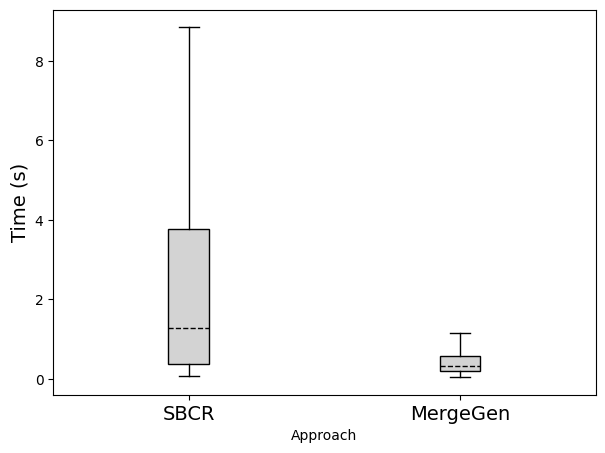

In [25]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_results_clean['time_sbcr'], df_results_clean['time_mergegen']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=False)

plt.xlabel('Approach')
plt.ylabel('Time (s)', fontsize=14)
plt.xticks([1, 2], ['SBCR', 'MergeGen'], fontsize=14)
# plt.title('Similarity between random candidates and parents \n using each aggregation function', fontsize=16)

# plt.savefig('RQ3_boxplots.png', dpi=300) 
plt.show()  